# Model characteristics
- Module validity verification
- Convergence investigation
- Robustness investigation

In [1]:
import json
import torch
import numpy as np
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from typing import Dict, Optional, Tuple, Union

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field
from matplotlib.ticker import MultipleLocator

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager


from utils.add_noise import add_event_noise
from utils.painter import extract_data, plot_curvegraph, plot_loss_curves, analyze_error, plot_exp111

# from methods import compute_flow_quantities
from gaussian_flow import GaussianFlowConfig, run_gaussian_flow

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)              
torch.cuda.manual_seed(seed)         
torch.cuda.manual_seed_all(seed)   

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

CUDA acceleration: OK
cuda


In [2]:
def save_results_to_json(results, save_path, indent=1):
    def convert_numpy_types(obj):
        if isinstance(obj, (np.integer, np.floating)): 
            return obj.item()
        elif isinstance(obj, np.ndarray): 
            return obj.tolist()
        return obj
    
    try:
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(results, f, ensure_ascii=False, indent=indent, default=convert_numpy_types)
        print(f"✅ Results saved to: {save_path}")
    except Exception as e:
        print(f"❌ Save failed: {e}")

In [3]:
flow0 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz")
flow1 = FlowManager(mode="data", data_path="./data/datasets/DNS_turbulence_00001_flow.npz")
flow2 = FlowManager(mode="data", data_path="./data/datasets/SQG_00001_flow.npz")

# flow0 = FlowManager(mode="analytical", name="cellular_flow", vmax=10, p=256)
# flow1 = FlowManager(mode="analytical", name="lamb_oseen", x_c=128, y_c=128, Gamma=5e3, rc=60)
# flow2 = FlowManager(mode="analytical", name="shear_flow", vmax=10, p=256)

flow_funcs = [flow0, flow1, flow2]
flow_names = ["JHTDB_isotropic", "DNS_turbulence", "SQG"]

## Module validity verification

In [4]:
jacobian_results = {}

for flow_index in tqdm(range(3), desc="Flows", position=0):

    flow_name = f"flow{flow_index}"
    jacobian_results[flow_name] = {}

    # ================= 数据生成 =================
    flow_func = globals()[flow_name].evaluate

    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05
    
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)

    evts, (u, v) = event_loader.load()
    flowgt = torch.stack([u, v], dim=0).to(device)
    
    events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
    h_gt = u.cpu().numpy()
    w_gt = v.cpu().numpy()

    configs = [
        (enable_jacobian, init_n)
        for enable_jacobian in [1, 0]
        for init_n in range(50, 510, 50)
    ]

    for enable_jacobian, init_n in tqdm(configs, desc=f"{flow_name}", leave=False, position=1):

        jac_key = str(enable_jacobian)
        if jac_key not in jacobian_results[flow_name]:
            jacobian_results[flow_name][jac_key] = {}

        rmse_list = []
        aee_list = []

        # ===== repeat 10 times =====
        for _ in tqdm(range(10), desc="repeat", leave=False, position=2):

            cfg = GaussianFlowConfig(verbose=False, init_n=init_n, enable_jacobian=enable_jacobian, phase=[500, 200, 250], iterations=300, lr_j=0.001)

            res = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)

            pred_h, pred_w = res.flow[0], res.flow[1]
            rmse, aee = PIVmetric(pred_h, pred_w, h_gt, w_gt, show=False)[:2]

            rmse_list.append(rmse)
            aee_list.append(aee)

        rmse_mean = round(float(np.mean(sorted(rmse_list)[1:-1])), 4)
        aee_mean = round(float(np.mean(sorted(aee_list)[1:-1])), 4)

        jacobian_results[flow_name][jac_key][str(init_n)] = {"rmse": rmse_mean, "aee": aee_mean}
save_results_to_json(jacobian_results, "./output/EXP1/jacobian_results.json", indent=1)

Flows:   0%|          | 0/3 [00:00<?, ?it/s]

flow0:   0%|          | 0/20 [00:00<?, ?it/s]

repeat:   0%|          | 0/10 [00:00<?, ?it/s]

repeat:   0%|          | 0/10 [00:00<?, ?it/s]

repeat:   0%|          | 0/10 [00:00<?, ?it/s]

...

repeat:   0%|          | 0/10 [00:00<?, ?it/s]

repeat:   0%|          | 0/10 [00:00<?, ?it/s]

repeat:   0%|          | 0/10 [00:00<?, ?it/s]

repeat:   0%|          | 0/10 [00:00<?, ?it/s]

✅ Results saved to: ./output/EXP1/jacobian_results.json


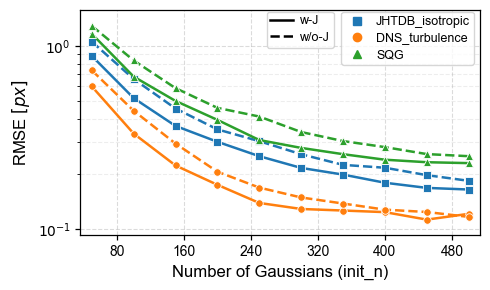

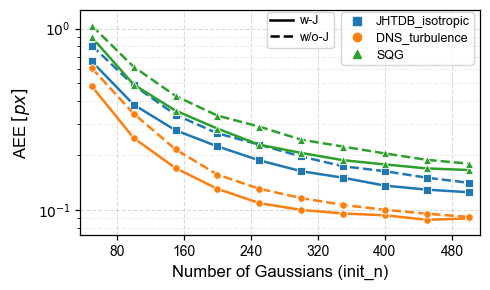

In [5]:
with open("./output/EXP1/jacobian_results.json", 'r', encoding='utf-8') as f:
    jacobian_data = json.load(f)
for metric in ["rmse", "aee"]:
    plot_exp111(jacobian_data, flow_names=flow_names, metric=metric, save_path = f"./output/EXP1/jacobian_{metric}.pdf")

## Convergence investigation

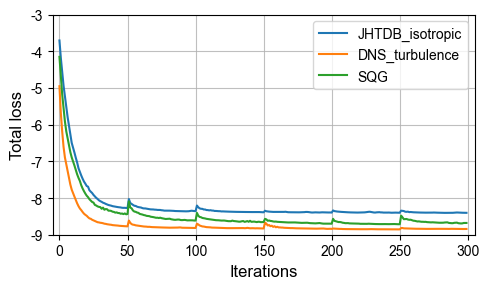

In [6]:
history = []

for flow_index in range(3):

    flow_n = f"flow{flow_index}"
    flow_func = globals()[flow_n].evaluate

    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05
    
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
    evts, (u, v) = event_loader.load()

    events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
    h_gt = u.cpu().numpy()
    w_gt = v.cpu().numpy()

    cfg = GaussianFlowConfig()

    res = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
    history.append(res.history)

plot_loss_curves(history, flow_names, save_path="./output/EXP1/fig6.pdf")

## Robustness investigation

- particle density

In [7]:
density_results = {}

for i in tqdm(range(3), desc="methods"):
    flow_func = globals()[f"flow{i}"].evaluate
    cfg_evts = config_events()
    cfg_evts.time_length = 4
    cfg_evts.d = 0.05

    single_flow_results = {}
    for density in tqdm([i / 100 for i in range(1, 11, 1)], desc=f"{flow_names[i]}-Density", leave=False):
        single_density_rmse = []
        single_density_aee = []
        
        for _ in range(10):
            cfg_evts.density = density
    
            event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
            evts, (u, v) = event_loader.load()

            u_gt, v_gt = u.cpu().numpy(), v.cpu().numpy()

            events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
            cfg = GaussianFlowConfig(lr_j=0.001)
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            
            pred_h, pred_w = result.flow[0], result.flow[1]
            res = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)
            rmse, aee = res[0], res[1]
            single_density_rmse.append(rmse)
            single_density_aee.append(aee)

        rmse_mean = np.mean(np.sort(single_density_rmse)[1:-1])
        aee_mean = np.mean(np.sort(single_density_aee)[1:-1])

        single_flow_results[f"{density:.6f}"] = {
            "rmse": round(float(rmse_mean), 4),
            "aee": round(float(aee_mean), 4)}

    density_results[flow_names[i]] = single_flow_results

save_results_to_json(density_results, "./output/EXP1/density_results.json", indent=1)

methods:   0%|          | 0/3 [00:00<?, ?it/s]

JHTDB_isotropic-Density:   0%|          | 0/10 [00:00<?, ?it/s]

DNS_turbulence-Density:   0%|          | 0/10 [00:00<?, ?it/s]

SQG-Density:   0%|          | 0/10 [00:00<?, ?it/s]

✅ Results saved to: ./output/EXP1/density_results.json


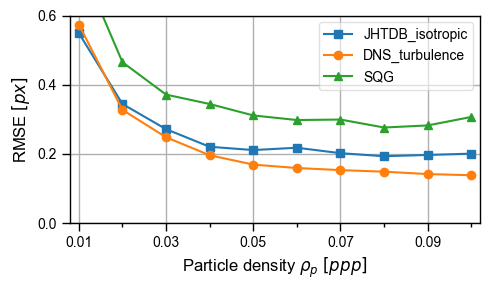

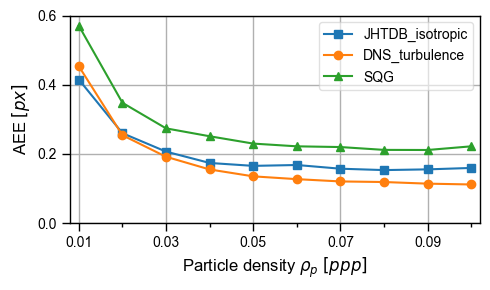

In [9]:
with open("./output/EXP1/density_results.json", 'r', encoding='utf-8') as f:
    density_data = json.load(f)
x_vals, y_rmse_list, y_aee_list = extract_data(density_data)

save_density = 1
if save_density == 1:
    rmse_path = "./output/EXP1/density_rmse.pdf"
    aee_path = "./output/EXP1/density_aee.pdf"
else:
    rmse_path = None
    aee_path = None

use_Chinese = 0
if use_Chinese ==1:
    use_chinese = True
    size = [14, 14, 18]
else:
    use_chinese = False
    size = [10, 10, 12]

legend_names_en = flow_names
y_major_ticks = [0, 0.2, 0.4, 0.6]
x_major_ticks = list(np.arange(0.01, 0.11, 0.02))
x_minor_ticks = list(np.arange(0.0, 0.11, 0.02))

plot_curvegraph(x_data=x_vals, y_data_list=y_rmse_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en='Particle density $\\rho_{p}$ $[ppp]$', xlabel_zh='粒子密度 $\\rho_{p}$', 
    ylabel_en="RMSE $[px]$", ylabel_zh="RMSE $[px]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(0.008, 0.102), ylim=(0, 0.6), 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=rmse_path, use_chinese=use_chinese)

plot_curvegraph(x_data=x_vals, y_data_list=y_aee_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en='Particle density $\\rho_{p}$ $[ppp]$', xlabel_zh='粒子密度 $\\rho_{p}$', 
    ylabel_en="AEE $[px]$", ylabel_zh="AEE $[px]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(0.008, 0.102), ylim=(0, 0.6), 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=aee_path, use_chinese=use_chinese)

- noise ratio

In [10]:
noise_results = {}

for i in tqdm(range(3), desc="flows"):
    flow_func = globals()[f"flow{i}"].evaluate
    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.density = 0.05
    cfg_evts.d = 0.5
    
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
    evts, (u, v) = event_loader.load()
    u_gt, v_gt = u.cpu().numpy(), v.cpu().numpy()

    single_flow_results = {}

    for j, noise_ratio in enumerate(tqdm(np.arange(0, 0.21, 0.02), desc=f"  Noise ratio", leave=False)):
        rmse_list, aee_list = [], []

        for k in range(10):
            events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
            noisy_events = add_event_noise(events, 256, 256 , noise_ratio = noise_ratio)
            
            cfg = GaussianFlowConfig()
            res = run_gaussian_flow(events=noisy_events, cfg=cfg, flowgt=None)
            pred_h, pred_w = res.flow[:2]
            rmse, aee = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)[:2]

            rmse_list.append(float(rmse))
            aee_list.append(float(aee))

        rmse_mean = np.mean(np.sort(rmse_list)[1:-1])
        aee_mean = np.mean(np.sort(aee_list)[1:-1])

        single_flow_results[f"{noise_ratio:.2f}"] = {
            "rmse": round(rmse_mean, 4),
            "aee": round(aee_mean, 4)
        }

    noise_results[flow_names[i]] = single_flow_results

save_results_to_json(noise_results, "./output/EXP1/noise_results.json", indent=1)

flows:   0%|          | 0/3 [00:00<?, ?it/s]

  Noise ratio:   0%|          | 0/11 [00:00<?, ?it/s]

  Noise ratio:   0%|          | 0/11 [00:00<?, ?it/s]

  Noise ratio:   0%|          | 0/11 [00:00<?, ?it/s]

✅ Results saved to: ./output/EXP1/noise_results.json


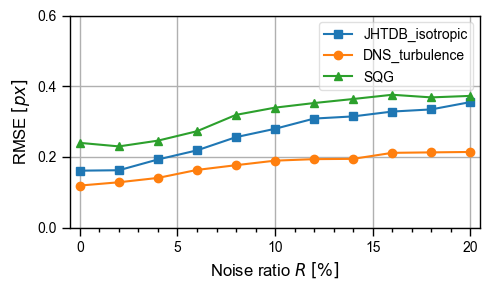

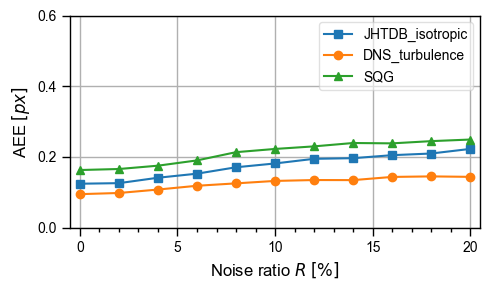

In [11]:
with open("./output/EXP1/noise_results.json", 'r', encoding='utf-8') as f:
    noise_data = json.load(f)
x_vals, y_rmse_list, y_aee_list = extract_data(noise_data)

legend_names_en = flow_names
y_major_ticks = [0, 0.2, 0.4, 0.6]

save_noise = 1
if save_noise == 1:
    rmse_path = "./output/EXP1/noise_rmse.pdf"
    aee_path = "./output/EXP1/noise_aee.pdf"
else:
    rmse_path = None
    aee_path = None

use_Chinese = 0
if use_Chinese ==1:
    use_chinese = True
    size = [14, 14, 18]
else:
    use_chinese = False
    size = [10, 10, 12]
    
x_major_ticks = list(range(0, 21, 5))
x_minor_ticks = list(range(1, 21, 1))

plot_curvegraph(x_data=x_vals*100, y_data_list=y_rmse_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en="Noise ratio $R$ $[\%]$", xlabel_zh="噪声比例 $R$ $[\%]$", 
    ylabel_en="RMSE $[px]$", ylabel_zh="RMSE $[px]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(-0.5, 20.5), ylim=(0, 0.6), 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=rmse_path, 
    use_chinese=use_chinese)

plot_curvegraph(x_data=x_vals*100, y_data_list=y_aee_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en="Noise ratio $R$ $[\%]$", xlabel_zh="噪声比例 $R$ $[\%]$", 
    ylabel_en="AEE $[px]$", ylabel_zh="AEE $[px]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(-0.5, 20.5), ylim=(0, 0.6), 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=aee_path, 
    use_chinese=use_chinese)